<a href="https://colab.research.google.com/github/faisu6339-glitch/RAG/blob/main/Text_Splitting_and_Chunking_in_RAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. What is text splitting?
Text splitting is the process of dividing a large document into smaller pieces of text.

These smaller pieces are called chunks.

Imagine you have a 100-page PDF containing DBMS notes.

If you send the entire PDF content directly to an embedding model, you may encounter:
- Input token limits.
- Less precise retrieval.
- Difficulty locating specific information.
- Higher processing costs.
Instead, we divide the document into smaller chunks

# Original document:
Python is a programming language.

Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.

Natural language processing works with human language.


After chunking:

Chunk 1
Python is a programming language.

Python supports object-oriented programming.


Chunk 2
Machine learning is a subset of artificial intelligence.


Chunk 3
Deep learning uses neural networks.

Natural language processing works with human language.


Each chunk becomes an individual unit that can be embedded and retrieved.

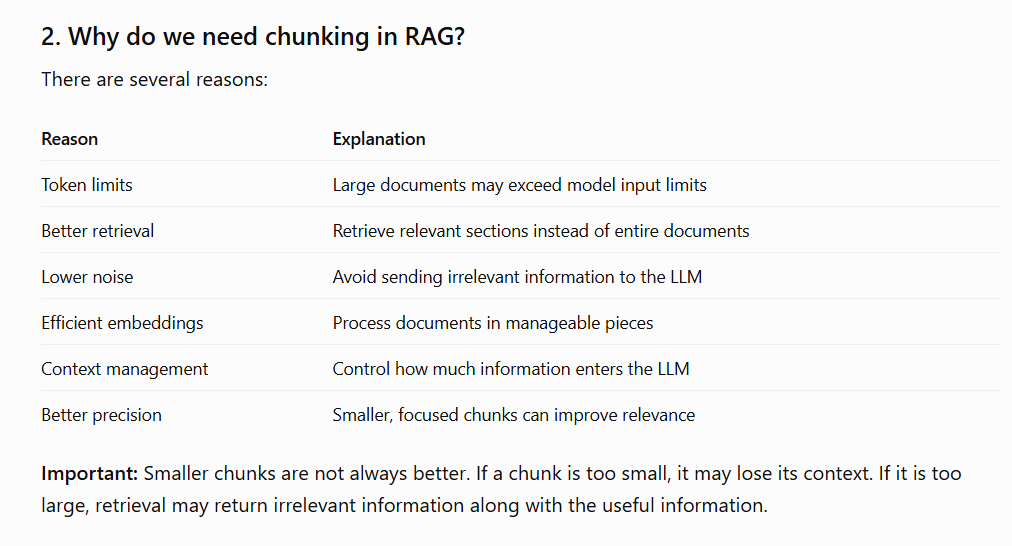

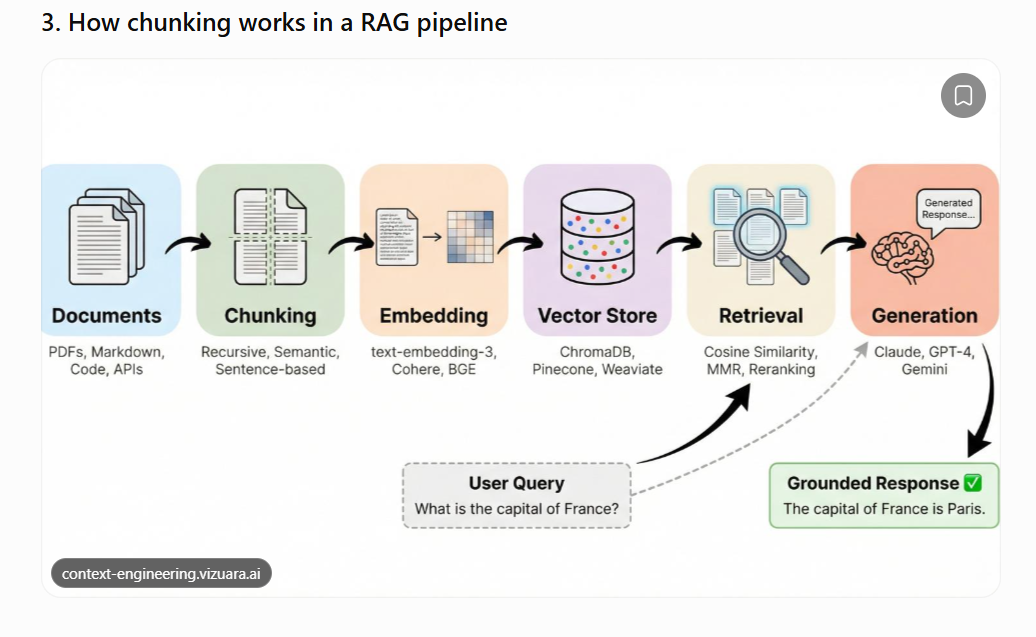

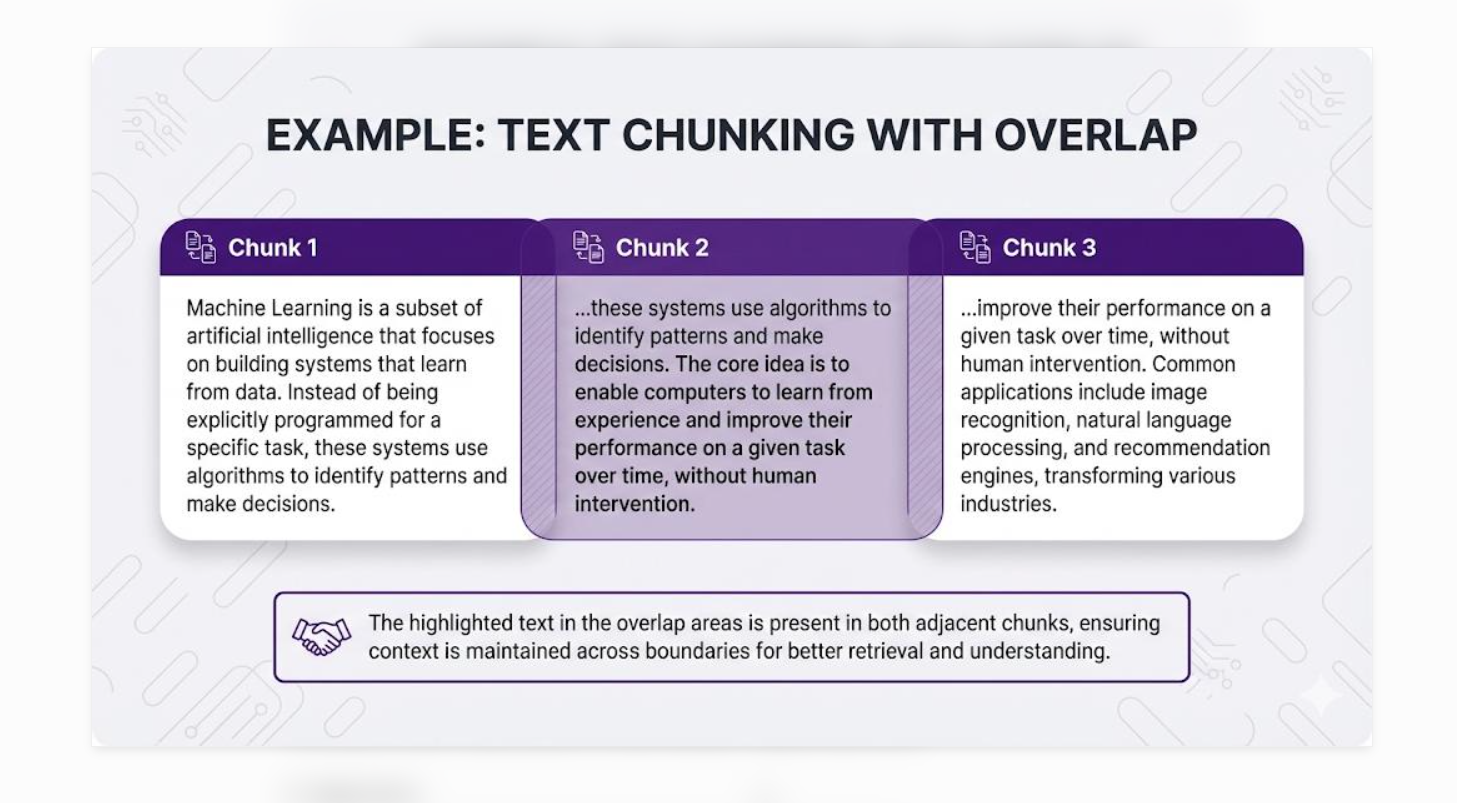

In [1]:
%pip install -qU langchain langchain-core langchain-community
%pip install -qU langchain-text-splitters
%pip install -qU langchain-nvidia-ai-endpoints
%pip install -qU pypdf pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.


In [2]:
from google.colab import userdata
import os

os.environ["NVIDIA_API_KEY"] = userdata.get("NVIDIA_API_KEY")

print("NVIDIA API configured successfully!")

NVIDIA API configured successfully!


# Program 1: Basic CharacterTextSplitter

In [3]:
from langchain_text_splitters import CharacterTextSplitter

text = """
Python is a programming language.

Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.

Natural language processing works with human language.
"""

splitter = CharacterTextSplitter(
    separator="\n\n",
    chunk_size=100,
    chunk_overlap=20,
    length_function=len
)

chunks = splitter.split_text(text)

for index, chunk in enumerate(chunks):

    print(f"\nChunk {index + 1}")

    print(chunk)

    print("Length:", len(chunk))

    print("-" * 40)


Chunk 1
Python is a programming language.

Python supports object-oriented programming.
Length: 79
----------------------------------------

Chunk 2
Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.
Length: 93
----------------------------------------

Chunk 3
Natural language processing works with human language.
Length: 54
----------------------------------------


# Program 2: CharacterTextSplitter with a different separator

In [4]:
from langchain_text_splitters import CharacterTextSplitter

text = """
Python is easy to learn.
Python supports OOP.
Machine learning uses data.
Deep learning uses neural networks.
"""

splitter = CharacterTextSplitter(
    separator=".",
    chunk_size=50,
    chunk_overlap=5,
    length_function=len
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):

    print(f"Chunk {i+1}: {chunk}")

Chunk 1: Python is easy to learn.
Python supports OOP
Chunk 2: Machine learning uses data
Chunk 3: Deep learning uses neural networks.


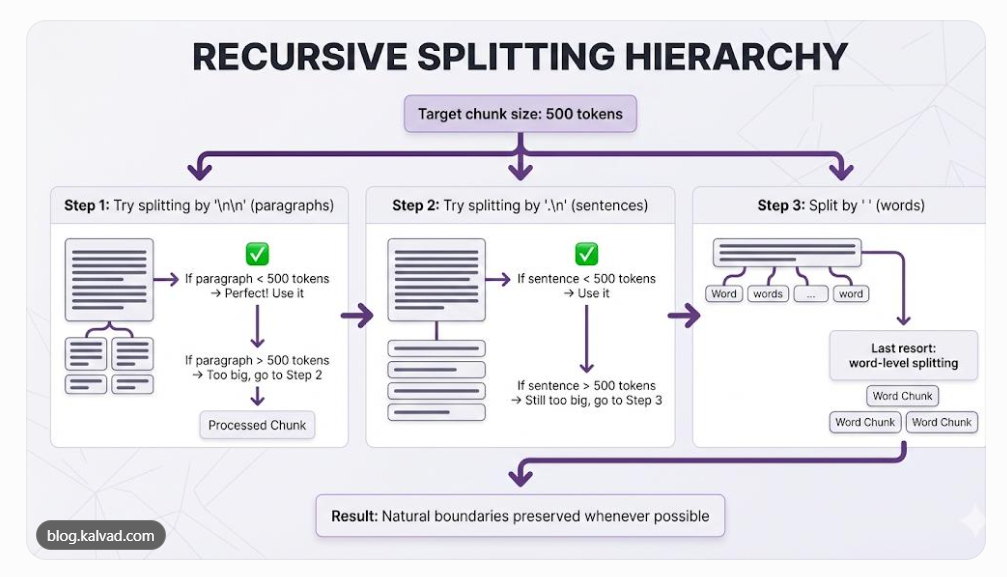

In [5]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Python is a high-level programming language.

Python supports object-oriented programming.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks to learn complex patterns.

Natural language processing allows computers to understand human language.
"""

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print(chunk)

    print("Length:", len(chunk))

    print("-" * 40)


Chunk 1
Python is a high-level programming language.

Python supports object-oriented programming.
Length: 90
----------------------------------------

Chunk 2
Machine learning is a subset of artificial intelligence.
Length: 56
----------------------------------------

Chunk 3
Deep learning uses neural networks to learn complex patterns.
Length: 61
----------------------------------------

Chunk 4
Natural language processing allows computers to understand human language.
Length: 74
----------------------------------------


# Program 6: Customize recursive separators

In [6]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text = """
Python is a programming language.
Python supports OOP.
Machine learning learns from data.
Deep learning uses neural networks.
"""

splitter = RecursiveCharacterTextSplitter(
    separators=[
        ". ",
        "\n",
        " ",
        ""
    ],
    chunk_size=60,
    chunk_overlap=10,
    length_function=len
)

chunks = splitter.split_text(text)

for chunk in chunks:

    print(chunk)

    print("-" * 30)

Python is a programming language.
Python supports OOP.
------------------------------
Machine learning learns from data.
------------------------------
Deep learning uses neural networks.
------------------------------


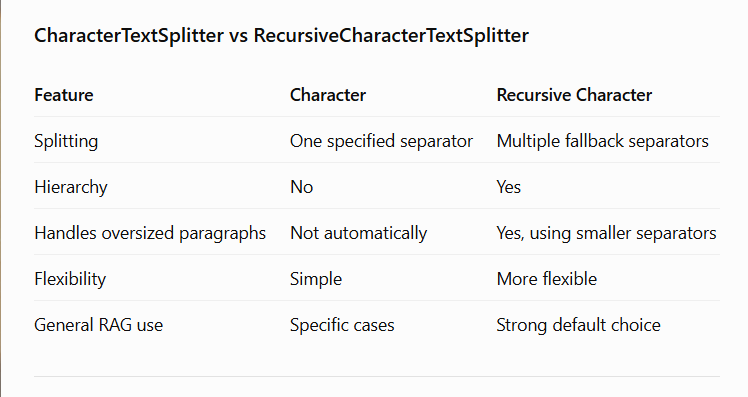

# Program 7: Split Documents and preserve metadata

In [7]:
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter

documents = [

    Document(
        page_content="""
        Python is a programming language.

        Python supports object-oriented programming.

        Python supports multiple programming paradigms.
        """,
        metadata={
            "source": "python.pdf",
            "page": 1
        }
    ),

    Document(
        page_content="""
        Machine learning is a subset of AI.

        It uses algorithms to learn patterns from data.

        Deep learning uses neural networks.
        """,
        metadata={
            "source": "ml.pdf",
            "page": 2
        }
    )
]

splitter = RecursiveCharacterTextSplitter(
    chunk_size=100,
    chunk_overlap=20
)

chunks = splitter.split_documents(documents)

print("Total chunks:", len(chunks))

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print("Content:", chunk.page_content)

    print("Metadata:", chunk.metadata)

    print("-" * 50)

Total chunks: 5

Chunk 1
Content: Python is a programming language.

        Python supports object-oriented programming.
Metadata: {'source': 'python.pdf', 'page': 1}
--------------------------------------------------

Chunk 2
Content: Python supports multiple programming paradigms.
Metadata: {'source': 'python.pdf', 'page': 1}
--------------------------------------------------

Chunk 3
Content: Machine learning is a subset of AI.
Metadata: {'source': 'ml.pdf', 'page': 2}
--------------------------------------------------

Chunk 4
Content: It uses algorithms to learn patterns from data.
Metadata: {'source': 'ml.pdf', 'page': 2}
--------------------------------------------------

Chunk 5
Content: Deep learning uses neural networks.
Metadata: {'source': 'ml.pdf', 'page': 2}
--------------------------------------------------


In [8]:
%pip install -qU tiktoken

# Program 8: Basic TokenTextSplitter

In [9]:
from langchain_text_splitters import TokenTextSplitter

text = """
Python is a high-level programming language.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.

Natural language processing works with human language.
"""

splitter = TokenTextSplitter(
    encoding_name="cl100k_base",
    chunk_size=50,
    chunk_overlap=10
)

chunks = splitter.split_text(text)

for i, chunk in enumerate(chunks):

    print(f"\nChunk {i+1}")

    print(chunk)

    print("-" * 40)


Chunk 1

Python is a high-level programming language.

Machine learning is a subset of artificial intelligence.

Deep learning uses neural networks.

Natural language processing works with human language.

----------------------------------------


# Program 9: Count tokens using tiktoken

In [11]:
import tiktoken

text = """
Python is a programming language.
Machine learning uses algorithms.
Deep learning uses neural networks.
"""

encoding = tiktoken.get_encoding("cl100k_base")

tokens = encoding.encode(text)

print("Total characters:", len(text))

print("Total tokens:", len(tokens))

print("Token IDs:", tokens)

Total characters: 105
Total tokens: 18
Token IDs: [198, 31380, 374, 264, 15840, 4221, 627, 22333, 6975, 5829, 26249, 627, 34564, 6975, 5829, 30828, 14488, 627]


# Program 10: Compare character count and token count

In [10]:
import tiktoken

texts = [
    "Python is easy.",
    "Artificial Intelligence is transforming technology.",
    "Natural Language Processing."
]

encoding = tiktoken.get_encoding("cl100k_base")

for text in texts:

    token_count = len(encoding.encode(text))

    print("Text:", text)

    print("Characters:", len(text))

    print("Tokens:", token_count)

    print("-" * 40)

Text: Python is easy.
Characters: 15
Tokens: 4
----------------------------------------
Text: Artificial Intelligence is transforming technology.
Characters: 51
Tokens: 7
----------------------------------------
Text: Natural Language Processing.
Characters: 28
Tokens: 4
----------------------------------------
